### Introduction

In the Sillage project, one of the main aspect of our app is using the user's answers to questionnaires to output a ranked list of destinations and activities. In this tutorial i'll take you throught the steps that transform user's answers to actual recommendations. 

### Dataset

In this notebook, we'll use an artificial dataset that i've selected to represent three different types of profiles. The topics of the questions in the questionnaire are based on a mix of some early research made by the Sillage team* and basic essencial questions such as budget and climate.

the dataset contains artificial users' answers to typical questions the Sillage app would ask. In this case the users either choose an answer or give a value from 1 to 10 to represent their feeling toward a certain topic (likertscale or multiple choice). 

The questions concern 6 typical topics important to travelers : budget, climate, adventure (unique activities), nature, culture and travel pace.

For the scale type of answers the actual question would be as such : How important is curlture for you when you travel ? 1 begin "Not important at all when i travel" and 10 begin "Culture is one of the most important aspect of traveling for me"

*source : https://rouxadvertising.com/2026/02/03/part-1-what-todays-travelers-are-really-looking-for-in-a-vacation-experience/ - typical expectation of modern travelers.

In [45]:
!pip install pandas

In [46]:
import pandas as pd

users = [

    {
        "user_id": "USER_001",
        "name": "Aurélie",
        "budget": 6,
        "climate": "Mild",
        "adventure": 4,
        "nature": 6,
        "culture": 5,
        "travel_pace": "Balanced"
    },

    {
        "user_id": "USER_002",
        "name": "Fabia",
        "budget": 8,
        "climate": "Hot",
        "adventure": 7,
        "nature": 8,
        "culture": 6,
        "travel_pace": "Intensive"
    },

    {
        "user_id": "USER_003",
        "name": "Loan",
        "budget": 3,
        "climate": "Cold",
        "adventure": 4,
        "nature": 5,
        "culture": 3,
        "travel_pace": "Relaxing"
    },

]

df = pd.DataFrame(users)

df.to_csv("fictional_vacation_users.csv", index=False)

display(df)

,user_id,name,budget,climate,adventure,nature,culture,travel_pace
0,USER_001,Aurélie,6,Mild,4,6,5,Balanced
1,USER_002,Fabia,8,Hot,7,8,6,Intensive
2,USER_003,Loan,3,Cold,4,5,3,Relaxing


### Data preprocessing 

In this step we adapt the data by assigning a value to previous text answers (multiple choice questions).

For climate : 
* cold = 1
* Mild = 5
* Hot = 10

For tavel pace :
* Relaxing = 1
* Balanced = 5
* Intensive = 10 

Note :  The way questions are asked by the Sillage questionnaires make it so that we avoid any risk of missing values or wrong type of data. Therefore these typical data preprocessing steps are not              needed here


In [47]:
# Encode categorical variables

climate_mapping = {
    "Cold": 1,
    "Mild": 5,
    "Hot": 10
}

pace_mapping = {
    "Relaxing": 1,
    "Balanced": 5,
    "Intensive": 10
}

df["climate_score"] = df["climate"].map(climate_mapping)
df["pace_score"] = df["travel_pace"].map(pace_mapping)


# Prepare fuzzy inputs

fuzzy_inputs = df[
    [
        "budget",
        "climate_score",
        "adventure",
        "nature",
        "culture",
        "pace_score"
    ]
].copy()

display(fuzzy_inputs)

,budget,climate_score,adventure,nature,culture,pace_score
0,6,5,4,6,5,5
1,8,10,7,8,6,10
2,3,1,4,5,3,1


### Destination Dataset

Here we make an adapted dataset that contains Destinations with there relative values for cost level, climate score, adventure, nature, culture and travel pace. The data is "already preprocessed" because only the system reads these values.

In [48]:
destinations = [

    {
        "destination": "Bali",
        "cost_level": 5,
        "climate_score": 10,
        "adventure": 8,
        "nature": 10,
        "culture": 8,
        "travel_pace": 5
    },

    {
        "destination": "Swiss Alps",
        "cost_level": 9,
        "climate_score": 1,
        "adventure": 10,
        "nature": 10,
        "culture": 5,
        "travel_pace": 8
    },

    {
        "destination": "Kyoto",
        "cost_level": 6,
        "climate_score": 5,
        "adventure": 3,
        "nature": 6,
        "culture": 10,
        "travel_pace": 5
    },

    {
        "destination": "Santorini",
        "cost_level": 8,
        "climate_score": 10,
        "adventure": 3,
        "nature": 7,
        "culture": 7,
        "travel_pace": 3
    },

    {
        "destination": "Costa Rica",
        "cost_level": 6,
        "climate_score": 10,
        "adventure": 9,
        "nature": 10,
        "culture": 6,
        "travel_pace": 8
    },

    {
        "destination": "Paris",
        "cost_level": 8,
        "climate_score": 5,
        "adventure": 2,
        "nature": 3,
        "culture": 10,
        "travel_pace": 8
    },

    {
        "destination": "Thailand",
        "cost_level": 4,
        "climate_score": 10,
        "adventure": 7,
        "nature": 8,
        "culture": 9,
        "travel_pace": 6
    },

    {
        "destination": "Norway",
        "cost_level": 9,
        "climate_score": 1,
        "adventure": 8,
        "nature": 10,
        "culture": 6,
        "travel_pace": 7
    },

    {
        "destination": "Morocco",
        "cost_level": 4,
        "climate_score": 10,
        "adventure": 7,
        "nature": 7,
        "culture": 10,
        "travel_pace": 7
    },

    {
        "destination": "Maldives",
        "cost_level": 10,
        "climate_score": 10,
        "adventure": 5,
        "nature": 9,
        "culture": 4,
        "travel_pace": 2
    }

]



dest_df = pd.DataFrame(destinations)

display(dest_df)

,destination,cost_level,climate_score,adventure,nature,culture,travel_pace
0,Bali,5,10,8,10,8,5
1,Swiss Alps,9,1,10,10,5,8
2,Kyoto,6,5,3,6,10,5
3,Santorini,8,10,3,7,7,3
4,Costa Rica,6,10,9,10,6,8
5,Paris,8,5,2,3,10,8
6,Thailand,4,10,7,8,9,6
7,Norway,9,1,8,10,6,7
8,Morocco,4,10,7,7,10,7
9,Maldives,10,10,5,9,4,2


### Destination representation

This example helps us visualize our different destinations based on culture and adventure. We can already speculate on which destination could be recommended to our three users. However this only takes into account two of our six variables so actual recommendations couldn't only rely on this garph.

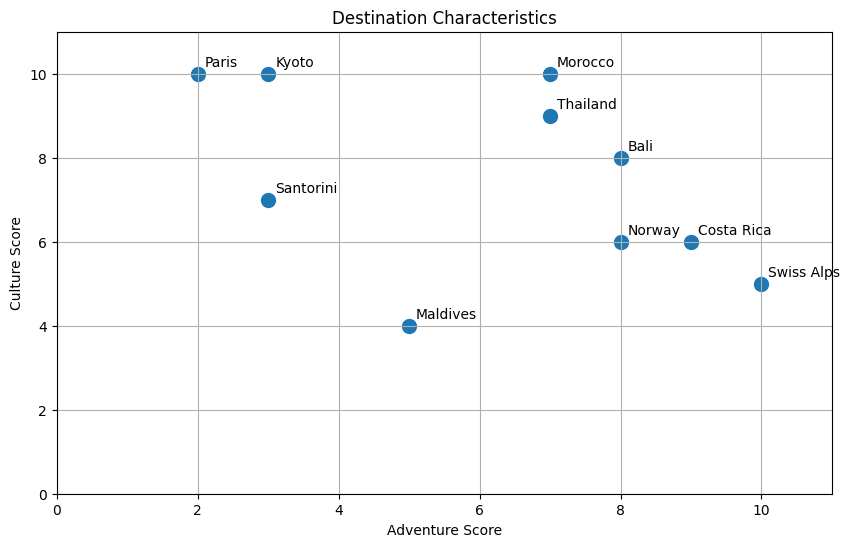

In [49]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    dest_df["adventure"],
    dest_df["culture"],
    s=100
)

for i, row in dest_df.iterrows():
    plt.annotate(
        row["destination"],
        (row["adventure"], row["culture"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Adventure Score")
plt.ylabel("Culture Score")
plt.title("Destination Characteristics")
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.grid()
plt.show()


### Fuzzy variables and memberships functions

We have six input variables that represent the compatibility between traveler and destination. 
Each variable has a univers of discourse to represent its compatibility score.

With automf() each variable is divided into three fuzzy sets : low, medium and high. There membership function overlap as can be seen in the "Membership function visualization" section below.

The output variable is the suitability of a destination. With fuzz.trimf we get three custom triangular membership functions to represent once again low, medium and high suitability.

The inputs membership functions are generated automaticaly. This is because they all scale from 0 to 10 and so the same approach can be applied consitently to all of them. But the output ones aren't, they are defined manualy. This let's us decide how these scores can be interpreted (from low to high).


In [50]:
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [51]:

# All input variables use a scale from 1 to 10
preference_universe = np.arange(1, 11, 1)

# Suitability score ranges from 0 to 100
suitability_universe = np.arange(0, 101, 1)

# Travelers preferences
budget_preference = ctrl.Antecedent(
    preference_universe, 'budget_preference')

climate_preference = ctrl.Antecedent(
    preference_universe, 'climate_preference')

adventure_preference = ctrl.Antecedent(
    preference_universe, 'adventure_preference')

nature_preference = ctrl.Antecedent(
    preference_universe, 'nature_preference')

culture_preference = ctrl.Antecedent(
    preference_universe, 'culture_preference')

pace_preference = ctrl.Antecedent(
    preference_universe, 'pace_preference')



# Destination characteristics
destination_cost = ctrl.Antecedent(
    preference_universe, 'destination_cost')

destination_climate = ctrl.Antecedent(
    preference_universe, 'destination_climate')

destination_adventure = ctrl.Antecedent(
    preference_universe, 'destination_adventure')

destination_nature = ctrl.Antecedent(
    preference_universe, 'destination_nature')

destination_culture = ctrl.Antecedent(
    preference_universe, 'destination_culture')

destination_pace = ctrl.Antecedent(
    preference_universe, 'destination_pace')


# Output
suitability = ctrl.Consequent(
    suitability_universe, 'suitability')




# Membership funtions (auto)
input_variables = [
    budget_preference,
    climate_preference,
    adventure_preference,
    nature_preference,
    culture_preference,
    pace_preference,

    destination_cost,
    destination_climate,
    destination_adventure,
    destination_nature,
    destination_culture,
    destination_pace
]

for variable in input_variables:
    variable.automf(3, names=['low', 'medium', 'high'])


# Membership funtions (custom)
suitability['low'] = fuzz.trimf(
    suitability.universe, [0, 0, 40])

suitability['medium'] = fuzz.trimf(
    suitability.universe, [20, 50, 80])

suitability['high'] = fuzz.trimf(
    suitability.universe, [60, 100, 100])


### Membership Functions visualization

The overlap of these function allows transitions in the suitability instead of strict categories.

C:\Users\Loan\master\sem3\fuzzysets\tutofuzzysets\fuzzy-tutorial-main\venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


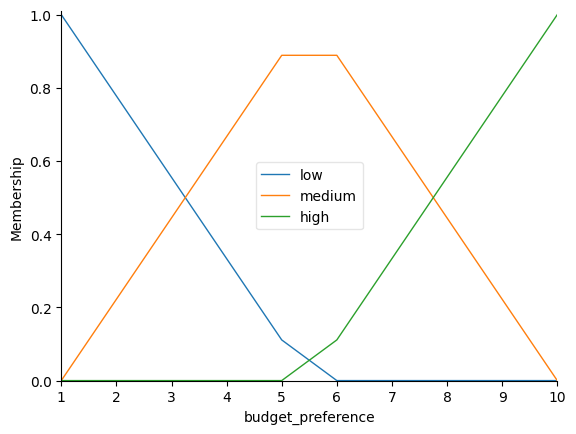

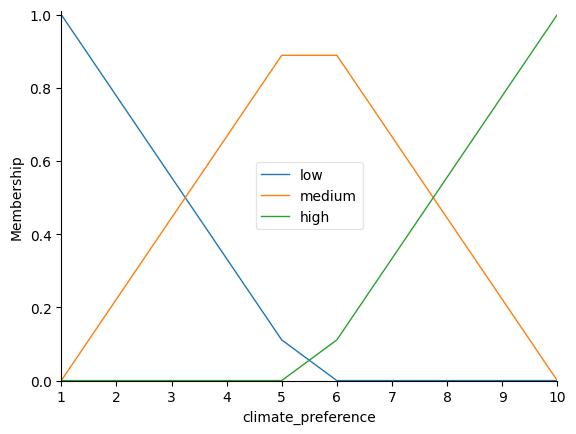

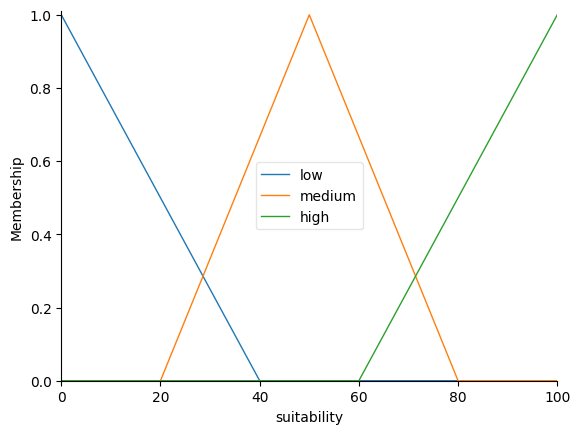

In [52]:
budget_preference.view()

climate_preference.view()

suitability.view()


### Fuzzy IF-THEN rules, compatibility scores

In [53]:

# Define compatibility functions

def budget_compatibility(budget, destination_cost):
    return max(0, 10 - 2 * max(0, destination_cost - budget))


def calculate_compatibility(preference, characteristic):
    return max(0, 10 - abs(preference - characteristic))


# Compare one traveller with one destination

def compare_traveller_destination(user, destination):

    compatibility = {

        "budget_compatibility": budget_compatibility(
            user["budget"],
            destination["cost_level"]
        ),

        "climate_compatibility": calculate_compatibility(
            user["climate_score"],
            destination["climate_score"]
        ),

        "adventure_compatibility": calculate_compatibility(
            user["adventure"],
            destination["adventure"]
        ),

        "nature_compatibility": calculate_compatibility(
            user["nature"],
            destination["nature"]
        ),

        "culture_compatibility": calculate_compatibility(
            user["culture"],
            destination["culture"]
        ),

        "pace_compatibility": calculate_compatibility(
            user["pace_score"],
            destination["travel_pace"]
        )
    }

    return compatibility


# Test with the first traveller and destination

user = df.iloc[0]
destination = dest_df.iloc[0]

test_result = compare_traveller_destination(
    user,
    destination
)

print("Traveller:", user["name"])
print("Destination:", destination["destination"])

print("\nCompatibility scores:")

for criterion, score in test_result.items():
    print(f"{criterion}: {score}/10")


Traveller: Aurélie
Destination: Bali

Compatibility scores:
budget_compatibility: 10/10
climate_compatibility: 5/10
adventure_compatibility: 6/10
nature_compatibility: 6/10
culture_compatibility: 7/10
pace_compatibility: 10/10


In [54]:

comparisons = []

for _, user in df.iterrows():

    for _, destination in dest_df.iterrows():

        scores = compare_traveller_destination(
            user,
            destination
        )

        result = {
            "user_id": user["user_id"],
            "name": user["name"],
            "destination": destination["destination"]
        }

        result.update(scores)

        comparisons.append(result)


# Convert results into a DataFrame

compatibility_df = pd.DataFrame(comparisons)

display(compatibility_df)

print("Total comparisons:", len(compatibility_df))


,user_id,name,destination,budget_compatibility,climate_compatibility,adventure_compatibility,nature_compatibility,culture_compatibility,pace_compatibility
0,USER_001,Aurélie,Bali,10,5,6,6,7,10
1,USER_001,Aurélie,Swiss Alps,4,6,4,6,10,7
2,USER_001,Aurélie,Kyoto,10,10,9,10,5,10
3,USER_001,Aurélie,Santorini,6,5,9,9,8,8
4,USER_001,Aurélie,Costa Rica,10,5,5,6,9,7
5,USER_001,Aurélie,Paris,6,10,8,7,5,7
6,USER_001,Aurélie,Thailand,10,5,7,8,6,9
7,USER_001,Aurélie,Norway,4,6,6,6,9,8
8,USER_001,Aurélie,Morocco,10,5,7,9,5,8
9,USER_001,Aurélie,Maldives,2,5,9,7,9,7


Total comparisons: 30


C:\Users\Loan\master\sem3\fuzzysets\tutofuzzysets\fuzzy-tutorial-main\venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


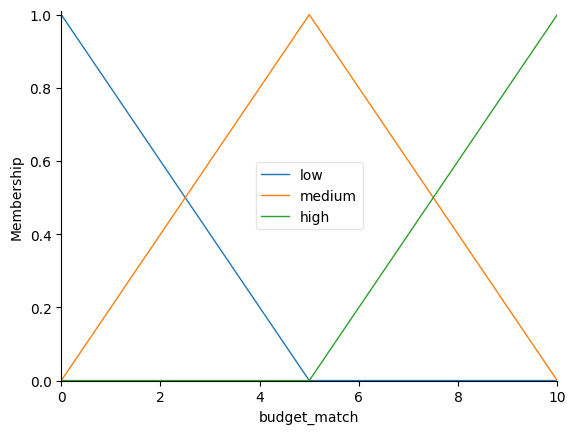

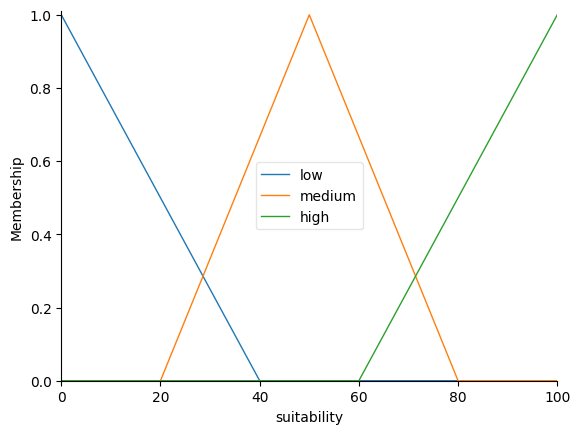

In [55]:

# Define compatibility inputs

compatibility_universe = np.arange(0, 11, 1)

budget_match = ctrl.Antecedent(
    compatibility_universe, 'budget_match'
)

climate_match = ctrl.Antecedent(
    compatibility_universe, 'climate_match'
)

adventure_match = ctrl.Antecedent(
    compatibility_universe, 'adventure_match'
)

nature_match = ctrl.Antecedent(
    compatibility_universe, 'nature_match'
)

culture_match = ctrl.Antecedent(
    compatibility_universe, 'culture_match'
)

pace_match = ctrl.Antecedent(
    compatibility_universe, 'pace_match'
)


# Define output

suitability = ctrl.Consequent(
    np.arange(0, 101, 1), 'suitability'
)


# Automatic membership functions

compatibility_variables = [
    budget_match,
    climate_match,
    adventure_match,
    nature_match,
    culture_match,
    pace_match
]

for variable in compatibility_variables:
    variable.automf(3, names=['low', 'medium', 'high'])


# Custom output membership functions

suitability['low'] = fuzz.trimf(
    suitability.universe, [0, 0, 40]
)

suitability['medium'] = fuzz.trimf(
    suitability.universe, [20, 50, 80]
)

suitability['high'] = fuzz.trimf(
    suitability.universe, [60, 100, 100]
)


# Visualize

budget_match.view()
suitability.view()


### Defining our fuzzy rules

For this example we'll define 8 rules, most of them pretty straight forward :
* Rule 1 : Excellent overall compatibility, high match for all variable = high suitability rating
* Rule 2 : Poor budget compatibility, los budget compatibility = low suitability rating
* Rule 3 : Poor climate compatibitily, low climate compatibility = low suitability rating
* Rule 4 : Strong nature and adventure compatibility, high compatibility for nature and adventure = high suitability rating
* Rule 5 : Strong cultural and pace compatibility, high compatibility for culture and travel pace = high suitability rating
* Rule 6 : Medium compatibility across all criteria, medium match for all variable = medium suitability rating
* Rule 7 : Good budget, climate and nature compatibility, high compatibility for budget, climate and nature = high suitability rating
* Rule 8 : Poor nature and adventure compatibility,
low compatibility for nature and adventure = low suitability rating


These rules allow us to refine the suitablitiy score of every destination for the corresponding user and in the end calculate which one is the best.

In [56]:

# Rule 1: Excellent overall compatibility
rule1 = ctrl.Rule(
    budget_match['high'] &
    climate_match['high'] &
    adventure_match['high'] &
    nature_match['high'] &
    culture_match['high'] &
    pace_match['high'],
    suitability['high']
)

# Rule 2: Poor budget compatibility
rule2 = ctrl.Rule(
    budget_match['low'],
    suitability['low']
)

# Rule 3: Poor climate compatibility
rule3 = ctrl.Rule(
    climate_match['low'],
    suitability['low']
)

# Rule 4: Strong nature and adventure compatibility
rule4 = ctrl.Rule(
    nature_match['high'] &
    adventure_match['high'],
    suitability['high']
)

# Rule 5: Strong cultural and pace compatibility
rule5 = ctrl.Rule(
    culture_match['high'] &
    pace_match['high'],
    suitability['high']
)

# Rule 6: Medium compatibility across all criteria
rule6 = ctrl.Rule(
    budget_match['medium'] &
    climate_match['medium'] &
    adventure_match['medium'] &
    nature_match['medium'] &
    culture_match['medium'] &
    pace_match['medium'],
    suitability['medium']
)

# Rule 7: Good budget, climate and nature compatibility
rule7 = ctrl.Rule(
    budget_match['high'] &
    climate_match['high'] &
    nature_match['high'],
    suitability['high']
)

# Rule 8: Poor nature and adventure compatibility
rule8 = ctrl.Rule(
    adventure_match['low'] &
    nature_match['low'],
    suitability['low']
)


### Final recommendations 
Based on the rules we've just defined we will now create and display the top recommendations for each user

In [57]:

vacation_ctrl = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4,
    rule5, rule6, rule7, rule8
])

vacation_simulation = ctrl.ControlSystemSimulation(
    vacation_ctrl
)

print("Fuzzy control system created successfully!")


Fuzzy control system created successfully!


### All recommendations

In [58]:
results = []

for _, row in compatibility_df.iterrows():

    vacation_simulation.reset()

    vacation_simulation.input['budget_match'] = row['budget_compatibility']
    vacation_simulation.input['climate_match'] = row['climate_compatibility']
    vacation_simulation.input['adventure_match'] = row['adventure_compatibility']
    vacation_simulation.input['nature_match'] = row['nature_compatibility']
    vacation_simulation.input['culture_match'] = row['culture_compatibility']
    vacation_simulation.input['pace_match'] = row['pace_compatibility']

    vacation_simulation.compute()

    results.append({
        'user_id': row['user_id'],
        'name': row['name'],
        'destination': row['destination'],
        'suitability_score': vacation_simulation.output['suitability']
    })

recommendations_df = pd.DataFrame(results)

display(recommendations_df)

,user_id,name,destination,suitability_score
0,USER_001,Aurélie,Bali,83.666667
1,USER_001,Aurélie,Swiss Alps,60.053333
2,USER_001,Aurélie,Kyoto,86.666667
3,USER_001,Aurélie,Santorini,73.445255
4,USER_001,Aurélie,Costa Rica,83.666667
5,USER_001,Aurélie,Paris,83.666667
6,USER_001,Aurélie,Thailand,83.666667
7,USER_001,Aurélie,Norway,62.180180
8,USER_001,Aurélie,Morocco,83.666667
9,USER_001,Aurélie,Maldives,45.469697


### All recommendations (ordered)

In [59]:
ranked_recommendations = recommendations_df.sort_values(
    by=['user_id', 'suitability_score'],
    ascending=[True, False]
)

display(ranked_recommendations)

,user_id,name,destination,suitability_score
2,USER_001,Aurélie,Kyoto,86.666667
0,USER_001,Aurélie,Bali,83.666667
4,USER_001,Aurélie,Costa Rica,83.666667
5,USER_001,Aurélie,Paris,83.666667
6,USER_001,Aurélie,Thailand,83.666667
8,USER_001,Aurélie,Morocco,83.666667
3,USER_001,Aurélie,Santorini,73.445255
7,USER_001,Aurélie,Norway,62.180180
1,USER_001,Aurélie,Swiss Alps,60.053333
9,USER_001,Aurélie,Maldives,45.469697


### Top 3 recommendations for each user

In [60]:
top_3_recommendations = (
    ranked_recommendations
    .groupby('user_id')
    .head(3)
    .reset_index(drop=True)
)

display(top_3_recommendations)

,user_id,name,destination,suitability_score
0,USER_001,Aurélie,Kyoto,86.666667
1,USER_001,Aurélie,Bali,83.666667
2,USER_001,Aurélie,Costa Rica,83.666667
3,USER_002,Fabia,Thailand,86.666667
4,USER_002,Fabia,Santorini,86.222222
5,USER_002,Fabia,Morocco,86.222222
6,USER_003,Loan,Kyoto,64.550000
7,USER_003,Loan,Maldives,49.034014
8,USER_003,Loan,Santorini,46.115942
